In [2]:
import matplotlib.pyplot as plt
import numpy as np

class MLP:
    def __init__(self, layer_sizes, activation='tanh'):
        if activation not in ('sigmoid', 'relu', 'tanh'):
            raise ValueError(f"Unknown activation {activation}")
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W, self.b = [], []
        self.Z_list, self.A_list = [], []
        self.dW_list = [np.zeros((layer_sizes[i], layer_sizes[i+1]))
                        for i in range(len(layer_sizes)-1)]
        self.db_list = [np.zeros((1, layer_sizes[i+1]))
                        for i in range(len(layer_sizes)-1)]

        for i in range(len(layer_sizes) - 1):
            in_dim, out_dim = layer_sizes[i], layer_sizes[i+1]
            self.W.append(np.random.randn(in_dim, out_dim) * 0.1)
            self.b.append(np.zeros((1, out_dim)))

    def _activate(self, Z):
        if self.activation == 'sigmoid':
            return 1 / (1 + np.exp(-Z))
        elif self.activation == 'relu':
            return np.maximum(0, Z)
        elif self.activation == 'tanh':
            return np.tanh(Z)

    def _dactivate(self, Z):
        if self.activation == 'sigmoid':
            s = 1 / (1 + np.exp(-Z))
            return s * (1 - s)
        elif self.activation == 'relu':
            return (Z > 0).astype(float)
        elif self.activation == 'tanh':
            return 1 - np.tanh(Z) ** 2

    def forward(self, X):
        self.Z_list, self.A_list = [], []
        A = X
        self.A_list.append(A)
        for i in range(len(self.W)):
            Z = A.dot(self.W[i]) + self.b[i]
            self.Z_list.append(Z)
            A = self._activate(Z) if i < len(self.W) - 1 else Z
            self.A_list.append(A)
        return A

    def mse(self, y_pred, y_true):
        return np.mean((y_pred - y_true) ** 2)

    def backward(self, y_true):
        m = y_true.shape[0]
        # выходной слой (линейный выход + MSE)
        aL = self.A_list[-1]
        delta = 2 * (aL - y_true) / m
        a_prev = self.A_list[-2]
        dW = a_prev.T.dot(delta)
        db = np.sum(delta, axis=0, keepdims=True)
        self.dW_list, self.db_list = [dW], [db]
        # скрытые слои
        for l in range(len(self.layer_sizes) - 2, 0, -1):
            z = self.Z_list[l - 1]
            a_prev = self.A_list[l - 1]
            W_next = self.W[l]
            delta = delta.dot(W_next.T) * self._dactivate(z)
            dW = a_prev.T.dot(delta)
            db = np.sum(delta, axis=0, keepdims=True)
            self.dW_list.insert(0, dW)
            self.db_list.insert(0, db)

    def update_params(self, lr):
        for i in range(len(self.W)):
            self.W[i] -= lr * self.dW_list[i]
            self.b[i] -= lr * self.db_list[i]
            

Epoch  50, loss=0.4057
Epoch 100, loss=0.1413
Epoch 150, loss=0.0887
Epoch 200, loss=0.0805
Epoch 250, loss=0.0761
Epoch 300, loss=0.0720


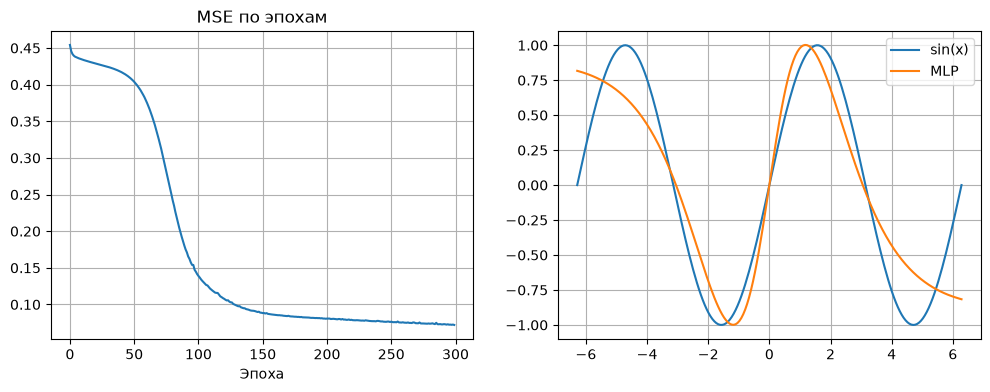

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- данные ----------
np.random.seed(0)
X = np.linspace(-2 * np.pi, 2 * np.pi, 300)[:, None]
y = np.sin(X)

# ---------- модель ----------
model = MLP([1, 32, 32, 1], activation='tanh')

# ---------- гиперпараметры ----------
lr = 0.01
epochs = 300
batch_size = 30
loss_history = []

# ---------- цикл обучения ----------
for epoch in range(1, epochs + 1):
    perm = np.random.permutation(len(X))
    X_sh, y_sh = X[perm], y[perm]

    for start in range(0, len(X), batch_size):
        xb = X_sh[start:start + batch_size]
        yb = y_sh[start:start + batch_size]

        model.forward(xb)          # прямой проход
        model.backward(yb)         # обратный проход
        model.update_params(lr)    # обновление параметров

    full_pred = model.forward(X)
    loss_history.append(model.mse(full_pred, y))

    if epoch % 50 == 0:
        print(f"Epoch {epoch:3d}, loss={loss_history[-1]:.4f}")

# ---------- визуализация ----------
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(loss_history)
plt.title("MSE по эпохам")
plt.xlabel("Эпоха")
plt.grid(True)

plt.subplot(1, 2, 2)
xx = np.linspace(-2 * np.pi, 2 * np.pi, 200)[:, None]
plt.plot(xx, np.sin(xx), label="sin(x)")
plt.plot(xx, model.predict(xx) if hasattr(model, 'predict') else model.forward(xx),
         label="MLP")
plt.legend()
plt.grid(True)
plt.show()